In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
categories = [
    'comp.graphics',
    'rec.autos',
    'sci.med',
    'sci.space'
]

dataset = fetch_20newsgroups(
    subset='all',
    categories=categories,
    remove=('headers', 'footers', 'quotes')
)

X = dataset.data
y = dataset.target

print("Dataset loaded successfully!")
print("Total documents:", len(X))
print("Number of classes:", len(dataset.target_names))
print("Classes:", dataset.target_names)

Dataset loaded successfully!
Total documents: 3940
Number of classes: 4
Classes: ['comp.graphics', 'rec.autos', 'sci.med', 'sci.space']


In [3]:
class_counts = pd.Series(y).value_counts().sort_index()

for i, name in enumerate(dataset.target_names):
    print(name, ":", class_counts[i])

comp.graphics : 973
rec.autos : 990
sci.med : 990
sci.space : 987


In [4]:
print("Sample news article:")
print(X[0][:1000])

print("\nActual category:")
print(dataset.target_names[y[0]])

Sample news article:
I am taking a course entitled "Exploring Science Using Internet".
For our final project, we are to find a compendium of Internet resources 
dealing with a science-related topic. I chose Astronomy. Anyway, I was 
wondering if anyone out there knew of any interesting resources on Internet
that provide information on Astronomy, space, NASA, or anything like that.

THANKS!

Actual category:
sci.space


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training documents:", len(X_train))
print("Testing documents:", len(X_test))

Training documents: 3152
Testing documents: 788


In [6]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    max_features=15000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training feature shape: (3152, 15000)
Testing feature shape: (788, 15000)
Number of TF-IDF features: 15000


In [7]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric='cosine',
        algorithm='brute'
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}

results = []
predictions = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average='macro', zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average='macro', zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average='macro', zero_division=0
    )

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("Completed:", name)

print("\nAll four models trained successfully!")


Training: Decision Tree
Completed: Decision Tree

Training: KNN
Completed: KNN

Training: SVM
Completed: SVM

Training: Naive Bayes
Completed: Naive Bayes

All four models trained successfully!


In [8]:
results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

    Algorithm  Accuracy  Precision  Recall  F1-Score
Decision Tree    0.7221     0.7274  0.7221    0.7220
          KNN    0.8439     0.8510  0.8441    0.8439
          SVM    0.8972     0.8994  0.8972    0.8970
  Naive Bayes    0.8985     0.9022  0.8985    0.8983


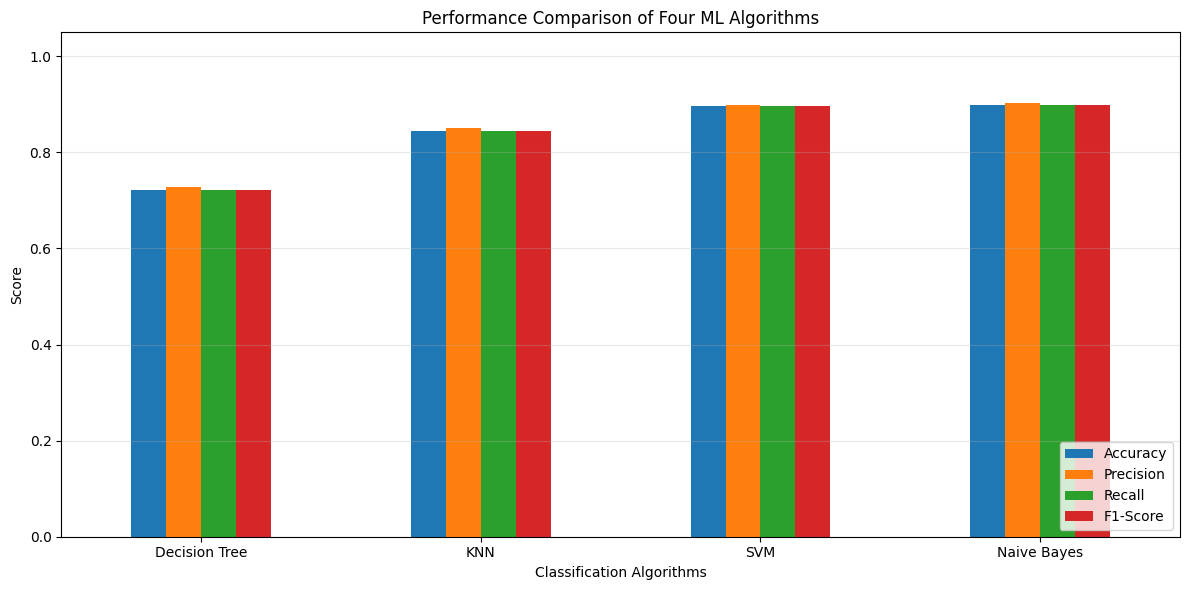

In [9]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results_df.set_index("Algorithm")[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Performance Comparison of Four ML Algorithms")
plt.ylabel("Score")
plt.xlabel("Classification Algorithms")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

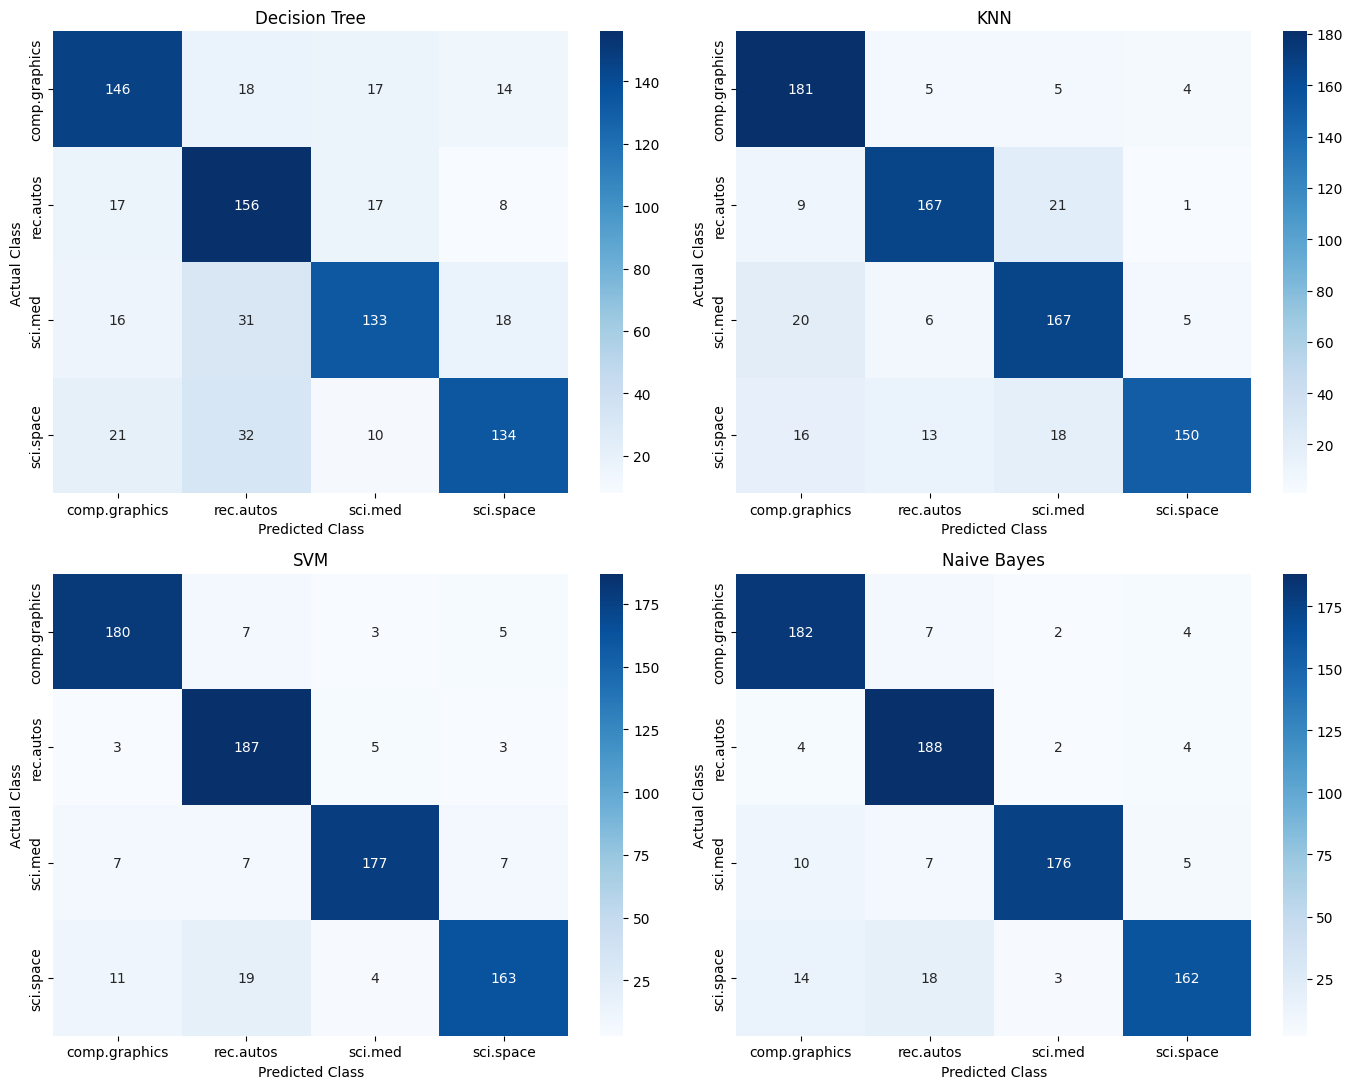

In [10]:
class_names = dataset.target_names

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=range(len(class_names))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [11]:
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Best Performing Algorithm:")
print(best_model["Algorithm"])

print("\nPerformance:")
print(best_model)

Best Performing Algorithm:
Naive Bayes

Performance:
Algorithm    Naive Bayes
Accuracy        0.898477
Precision       0.902169
Recall          0.898513
F1-Score        0.898285
Name: 3, dtype: object


In [12]:
for name, y_pred in predictions.items():

    print("\nClassification Report:", name)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=class_names,
            zero_division=0
        )
    )


Classification Report: Decision Tree
               precision    recall  f1-score   support

comp.graphics       0.73      0.75      0.74       195
    rec.autos       0.66      0.79      0.72       198
      sci.med       0.75      0.67      0.71       198
    sci.space       0.77      0.68      0.72       197

     accuracy                           0.72       788
    macro avg       0.73      0.72      0.72       788
 weighted avg       0.73      0.72      0.72       788


Classification Report: KNN
               precision    recall  f1-score   support

comp.graphics       0.80      0.93      0.86       195
    rec.autos       0.87      0.84      0.86       198
      sci.med       0.79      0.84      0.82       198
    sci.space       0.94      0.76      0.84       197

     accuracy                           0.84       788
    macro avg       0.85      0.84      0.84       788
 weighted avg       0.85      0.84      0.84       788


Classification Report: SVM
               preci

In [13]:
# Original SVM
svm_original = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=5000
)

svm_original.fit(X_train_tfidf, y_train)

original_pred = svm_original.predict(X_test_tfidf)

original_f1 = f1_score(
    y_test, original_pred, average='macro'
)


# Modified SVM
svm_modified = LinearSVC(
    C=0.1,
    random_state=42,
    max_iter=5000
)

svm_modified.fit(X_train_tfidf, y_train)

modified_pred = svm_modified.predict(X_test_tfidf)

modified_f1 = f1_score(
    y_test, modified_pred, average='macro'
)


print("Original SVM F1-score:", original_f1)
print("Modified SVM F1-score:", modified_f1)

print("Difference:", modified_f1 - original_f1)

Original SVM F1-score: 0.896972441675012
Modified SVM F1-score: 0.8970798477397739
Difference: 0.00010740606476189463


In [14]:
results_df.to_csv(
    "classification_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [15]:
print(results_df)

       Algorithm  Accuracy  Precision    Recall  F1-Score
0  Decision Tree  0.722081   0.727439  0.722129  0.722047
1            KNN  0.843909   0.851050  0.844124  0.843858
2            SVM  0.897208   0.899440  0.897218  0.896972
3    Naive Bayes  0.898477   0.902169  0.898513  0.898285


In [16]:
print("Best Model:")
print(results_df.loc[results_df["F1-Score"].idxmax()])

Best Model:
Algorithm    Naive Bayes
Accuracy        0.898477
Precision       0.902169
Recall          0.898513
F1-Score        0.898285
Name: 3, dtype: object
